Original shape: (569, 30)
Classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


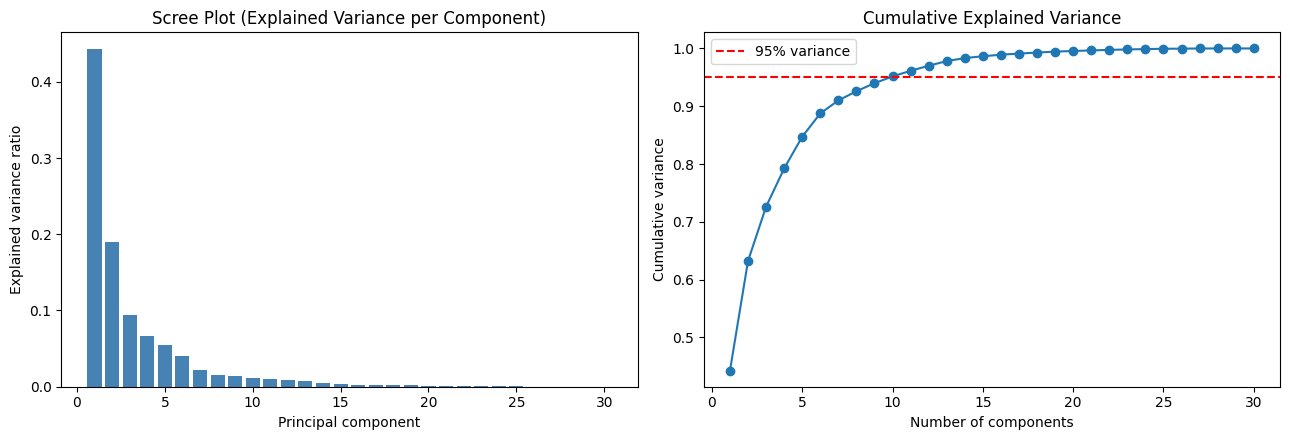


Components needed for 95% variance: 10 (out of 30)
Reduced shape: (569, 10)
Variance retained: 95.16 %


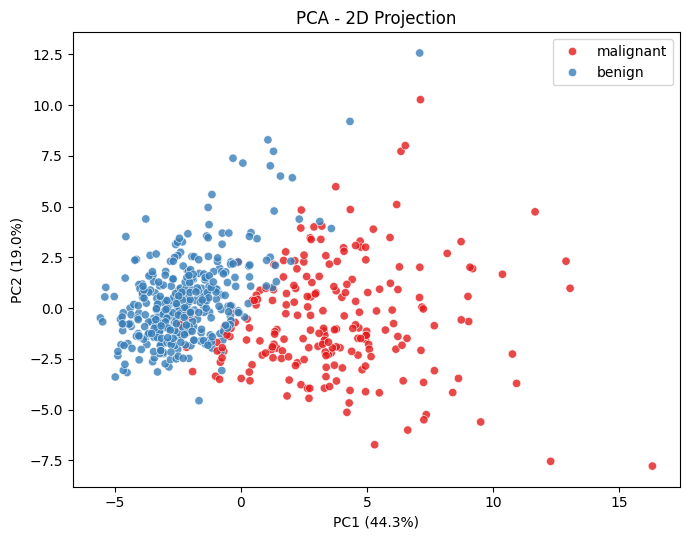

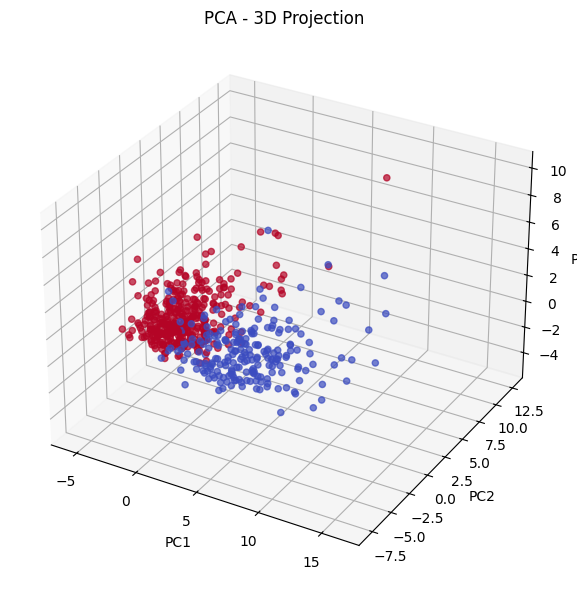


Classifier comparison (Logistic Regression):
Original (scaled) features          features = 30  accuracy = 0.9825
PCA (10 components, 95% var)        features = 10  accuracy = 0.9649
PCA (2 components)                  features = 2   accuracy = 0.9474

Top features contributing to PC1:
 mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
Name: PC1, dtype: float64


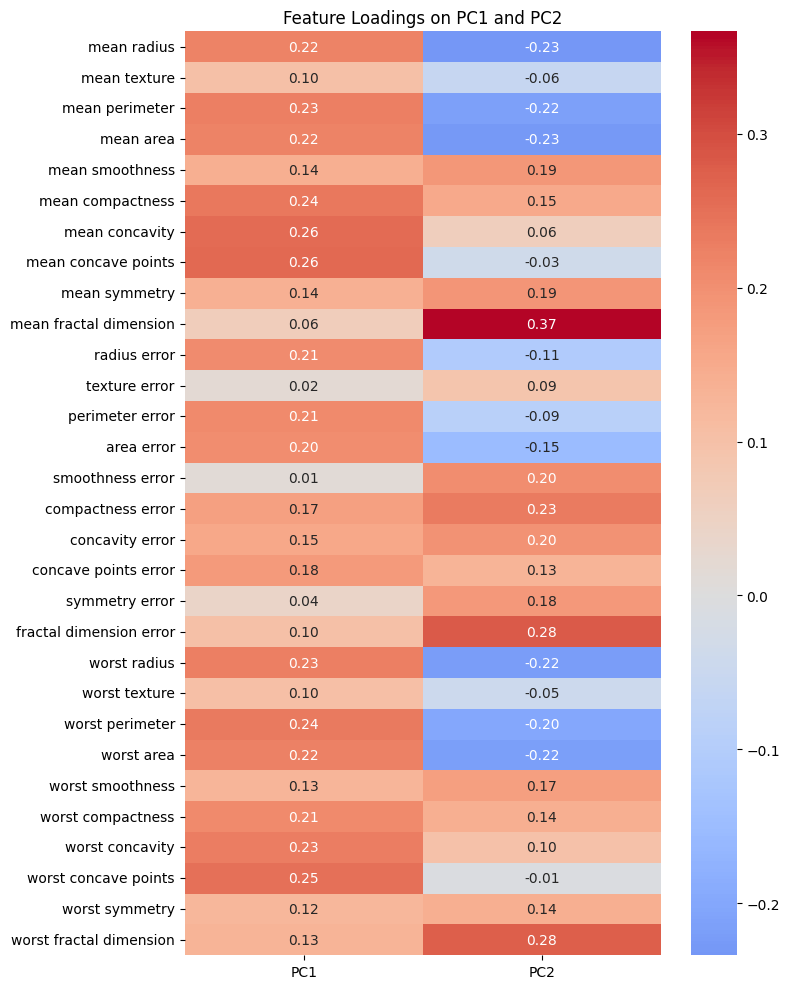


Conclusion: PCA reduced the data from 30 to 10 dimensions while keeping 95% of the variance, with very little change in classification accuracy.


In [ ]:
"""
Assignment 3: Apply dimensionality reduction using PCA.

Steps:
  1. Load a high-dimensional dataset (Breast Cancer: 30 features)
  2. Standardize the data (PCA is sensitive to scale)
  3. Apply PCA and study explained variance (scree plot, cumulative variance)
  4. Choose the number of components (95% variance)
  5. Visualize data in 2D / 3D
  6. Compare classifier accuracy: original features vs PCA-reduced features
  7. Inspect feature loadings of the principal components

Install: pip install pandas numpy matplotlib seaborn scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
print("Original shape:", X.shape)
print("Classes:", dict(zip(data.target_names, np.bincount(y))))

# ------------------------------------------------------------------
# 2. Standardize
# ------------------------------------------------------------------
X_scaled = StandardScaler().fit_transform(X)

# ------------------------------------------------------------------
# 3. Fit PCA with all components and study explained variance
# ------------------------------------------------------------------
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, len(explained) + 1), explained, color="steelblue")
ax[0].set_title("Scree Plot (Explained Variance per Component)")
ax[0].set_xlabel("Principal component")
ax[0].set_ylabel("Explained variance ratio")

ax[1].plot(range(1, len(cumulative) + 1), cumulative, "o-")
ax[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
ax[1].set_title("Cumulative Explained Variance")
ax[1].set_xlabel("Number of components")
ax[1].set_ylabel("Cumulative variance")
ax[1].legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 4. Choose number of components that keep 95% variance
# ------------------------------------------------------------------
n_95 = int(np.argmax(cumulative >= 0.95) + 1)
print(f"\nComponents needed for 95% variance: {n_95} (out of {X.shape[1]})")

pca = PCA(n_components=0.95)            # float = keep this much variance
X_pca = pca.fit_transform(X_scaled)
print("Reduced shape:", X_pca.shape)
print("Variance retained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# ------------------------------------------------------------------
# 5. Visualize in 2D and 3D
# ------------------------------------------------------------------
pca_2d = PCA(n_components=2).fit(X_scaled)
X_2d = pca_2d.transform(X_scaled)

plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1],
                hue=data.target_names[y], palette="Set1", alpha=0.8)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA - 2D Projection")
plt.tight_layout()
plt.show()

X_3d = PCA(n_components=3).fit_transform(X_scaled)
fig = plt.figure(figsize=(8, 6))
ax3 = fig.add_subplot(111, projection="3d")
sc = ax3.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=y, cmap="coolwarm", alpha=0.7)
ax3.set_xlabel("PC1")
ax3.set_ylabel("PC2")
ax3.set_zlabel("PC3")
ax3.set_title("PCA - 3D Projection")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 6. Model performance: original vs PCA features
# ------------------------------------------------------------------
def fit_and_score(features, label):
    X_tr, X_te, y_tr, y_te = train_test_split(
        features, y, test_size=0.2, random_state=42, stratify=y)
    model = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    acc = accuracy_score(y_te, model.predict(X_te))
    print(f"{label:<35} features = {features.shape[1]:<3} accuracy = {acc:.4f}")
    return acc


print("\nClassifier comparison (Logistic Regression):")
fit_and_score(X_scaled, "Original (scaled) features")
fit_and_score(X_pca, f"PCA ({n_95} components, 95% var)")
fit_and_score(X_2d, "PCA (2 components)")

# ------------------------------------------------------------------
# 7. Feature loadings: which original features drive each component
# ------------------------------------------------------------------
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns)

print("\nTop features contributing to PC1:\n",
      loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))

plt.figure(figsize=(8, 10))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Loadings on PC1 and PC2")
plt.tight_layout()
plt.show()

print("\nConclusion: PCA reduced the data from "
      f"{X.shape[1]} to {n_95} dimensions while keeping 95% of the variance, "
      "with very little change in classification accuracy.")